# Веломаршрут по популярным улицам

Постройте маршруты A–B по улицам, где действительно ездят велосипедисты, не сильно длиннее кратчайшего пути.
Популярность улиц — поездки STADTRADELN 2024 в Констанце. Итог считается на закрытой части города.
Меняйте ячейки с ✏️.

In [1]:
from pathlib import Path
import sys

import networkx as nx
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from cycle_routing.graph import drop_values
from cycle_routing.workshop import (
    build_network, comfort_cost, data_dictionary, example_rows, export_solution, gpx_table,
    load_city, ml_feature, presets, preview_cost, preview_features, score, solution, train_custom_model,
    train_popularity,
)
from cycle_routing.tags import has_any
from cycle_routing.routing import edge_bearings
from cycle_routing.workshop_maps import plot_network, plot_pairs, plot_popularity, plot_turn_examples, route_explorer

PACK = "konstanz_more"  # набор данных: другое разбиение города — другое имя
city = load_city(ROOT / "notebooks/data/hackathon" / PACK)
OUTPUT = ROOT / "outputs/hackathon" / PACK

## 1. Данные

`city.roads` — участки дорог, `city.trips` — поездки по участку (известны только в открытой части города),
`city.pairs` — тестовые пары. `data_dictionary` описывает исходные столбцы `city.roads`.
Имена столбцов и значения категорий — по-русски с подчёркиваниями: например, `пешеходная_дорожка`, `асфальт`.
Эти же значения используйте в фильтрах и признаках. Ниже — словарь и примеры заполненных строк.

In [2]:
display(data_dictionary(city))
display(example_rows(city))

,тип,значения
длина_м,"число, м",0.287916 … 2980.02
тип_дороги,категория,"пешеходная_дорожка, служебный_проезд, жилая_улица, тропа, хозяйственная_дорога, лестница, дорога_второго_значения, жилая_зона, местная_дорога, велодорожка, главная_дорога, прочая_местная_дорога, пешеходная_улица, съезд_со_скоростной_дороги, коридор, съезд_с_главной_дороги, автобусная_остановка, скоростная_дорога, автомагистраль, съезд_с_дороги_второго_значения, съезд_с_местной_дороги, съезд_с_автомагистрали, конная_дорожка"
покрытие,категория,"асфальт, тротуарная_плитка, мелкий_гравий, гравий, уплотнённая_смесь, нет_твёрдого_покрытия, галька, трава, брусчатка, грунт_без_покрытия, бетон, твёрдое_покрытие, грунт, щепа, дерево, газонная_решётка, земля, бетонные_плиты, металл, необработанный_булыжник, камень, грязь, скала, резина, булыжник, песок, металлическая_решётка, спортивное_покрытие, неопределённое_покрытие_нестандартный_тег, бетонные_колеи; пусто — нет данных"
ровность,категория,"хорошая, отличная, средняя, плохая, очень_плохая, крайне_плохая, для_обычных_колёс, ужасная, для_прочных_колёс, для_маленьких_колёс, нужен_высокий_клиренс, для_внедорожных_колёс, непроезжая, для_узких_колёс, для_специальных_внедорожных_колёс; пусто — нет данных"
велополоса,категория,"нет, велодорожка_отдельной_линией_osm, велополоса, отделённая_велодорожка, совместно_с_автобусами, велопереезд, совместная_полоса_с_машинами, предназначена_для_велосипедов, есть; пусто — нет данных"
велосипед,категория,"предназначено_для_велосипедов, разрешён, запрещён, использовать_соседнюю_велодорожку, спешиться, только_для_сельхозработ, только_для_лесных_работ, с_разрешения_владельца, не_рекомендуется, только_к_месту_назначения, неизвестно; пусто — нет данных"
освещение,категория,"есть, нет, автоматическое, круглосуточное, ограниченное; пусто — нет данных"
служебный_проезд,категория,"подъезд_к_зданию, проезд_по_парковке, узкий_проезд, проезд_через_обслуживание, проезд_экстренных_служб, спуск_к_воде, служебный_проезд, въезд_в_подземный_гараж; пусто — нет данных"
доступ,категория,"частный, запрещён, разрешён, с_разрешения_владельца, только_для_клиентов, только_к_месту_назначения, только_для_доставки, только_для_сельхозработ, по_пропуску, для_указанного_транспорта, только_для_лесных_работ; пусто — нет данных"
макс_скорость,"число, км/ч",5 … 100; пусто — нет данных


,длина_м,тип_дороги,покрытие,ровность,велополоса,велосипед,освещение,служебный_проезд,доступ,макс_скорость,полос,ширина_м,одностороннее
641,17.386630,местная_дорога,асфальт,отличная,нет,разрешён,нет,NaN,разрешён,60.0,2.0,7.5,False
12112,35.823359,жилая_улица;служебный_проезд,асфальт,отличная,нет,NaN,есть,подъезд_к_зданию,частный,30.0,NaN,NaN,False


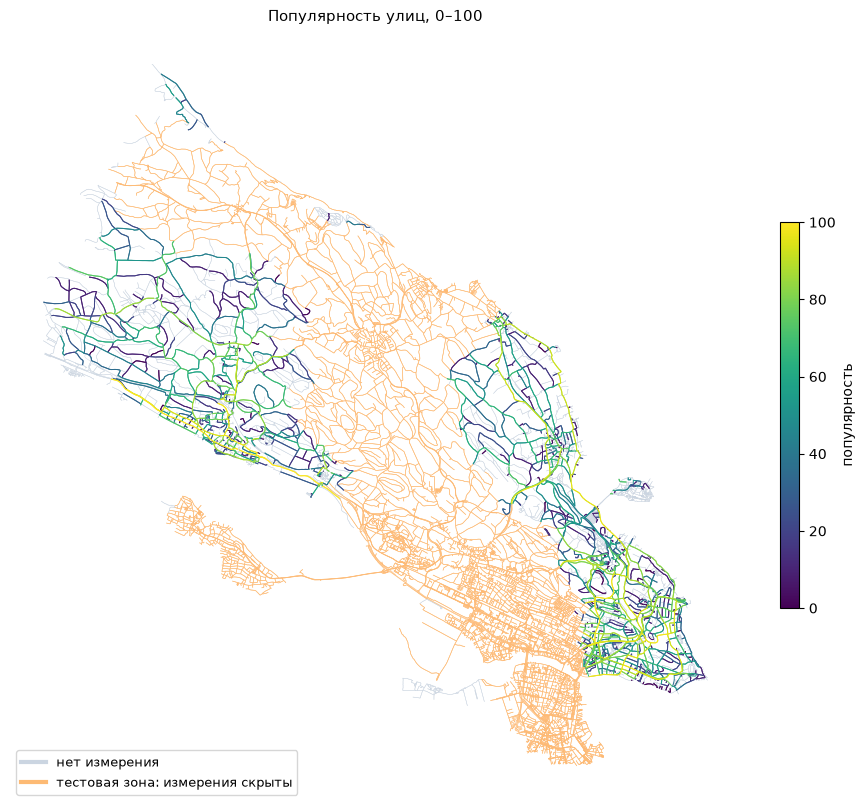

In [3]:
plot_popularity(city);

## 2. Фильтр ✏️

Какие дороги можно использовать. Участки, оторванные от основной сети, в маршрутах не используются.
Ниже весь код `rideable`: проверяем тип дороги, доступ и разрешение велосипеда.
Явное разрешение велосипеда отменяет ограничение доступа, но не запрет типа дороги.
Пешеходные дорожки сохраняются, если нет явного запрета велосипеда.

In [4]:
def rideable(roads):
    # Типы дорог, исключаемые из сети независимо от остальных тегов.
    forbidden_road = has_any(roads["тип_дороги"], {
        "лестница", "автомагистраль", "съезд_с_автомагистрали", "скоростная_дорога",
        "съезд_со_скоростной_дороги", "строящаяся_дорога", "предлагаемая_дорога",
        "планируемая_дорога", "снесённая_дорога", "заброшенная_дорога", "платформа",
        "лифт", "эскалатор", "коридор", "направляемая_автобусная_дорога",
        "гоночная_трасса", "автобусная_дорога",
    })

    # Закрытый доступ или частный служебный проезд.
    closed_access = has_any(roads["доступ"], {
        "частный", "запрещён", "только_для_клиентов", "по_пропуску", "только_для_доставки",
    }) | has_any(roads["служебный_проезд"], "частный_проезд")

    # Велосипед может быть разрешён даже при ограничении общего доступа.
    bicycle_allowed = has_any(roads["велосипед"], {
        "разрешён", "предназначено_для_велосипедов", "с_разрешения_владельца",
    })
    bicycle_forbidden = has_any(roads["велосипед"], {"запрещён", "спешиться", "частный_доступ"})

    return ~(forbidden_road | bicycle_forbidden | (closed_access & ~bicycle_allowed))

Осталось 38,333 участков (2528 км) из 44,460. Фильтр убрал 4,155 (261 км), оторвано от основной сети и не используется 1,972 (60 км).


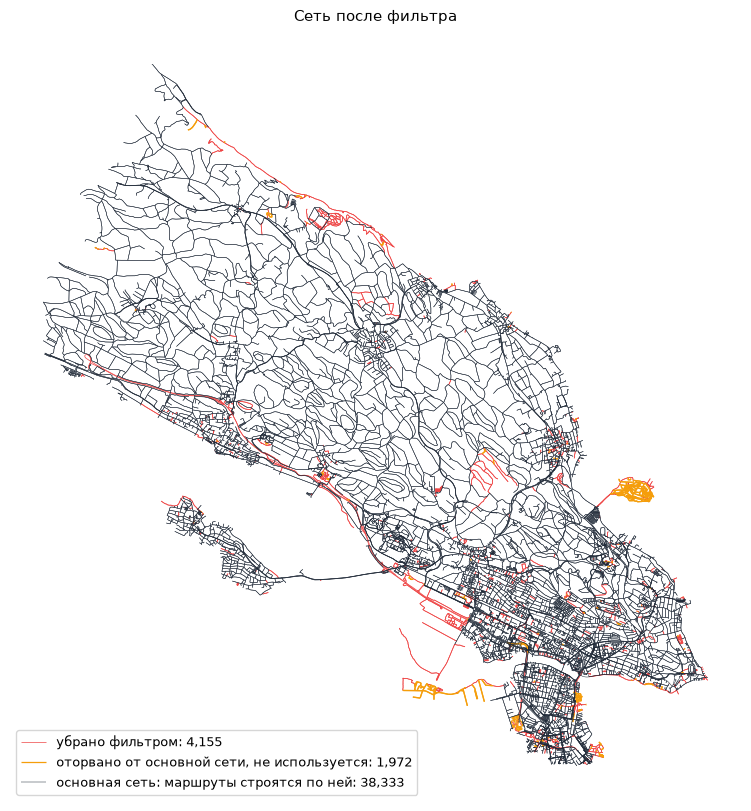

In [5]:
def keep(roads):
    ok = rideable(roads)  # готовый фильтр: без лестниц, запретов для велосипеда и частных проездов
    # ok &= drop_values(roads, тип_дороги=["главная_дорога"])  # пример: ещё убрать крупные дороги
    return ok

network = build_network(city, keep)
print(network.summary())
plot_network(network);

## 3. Тестовые пары

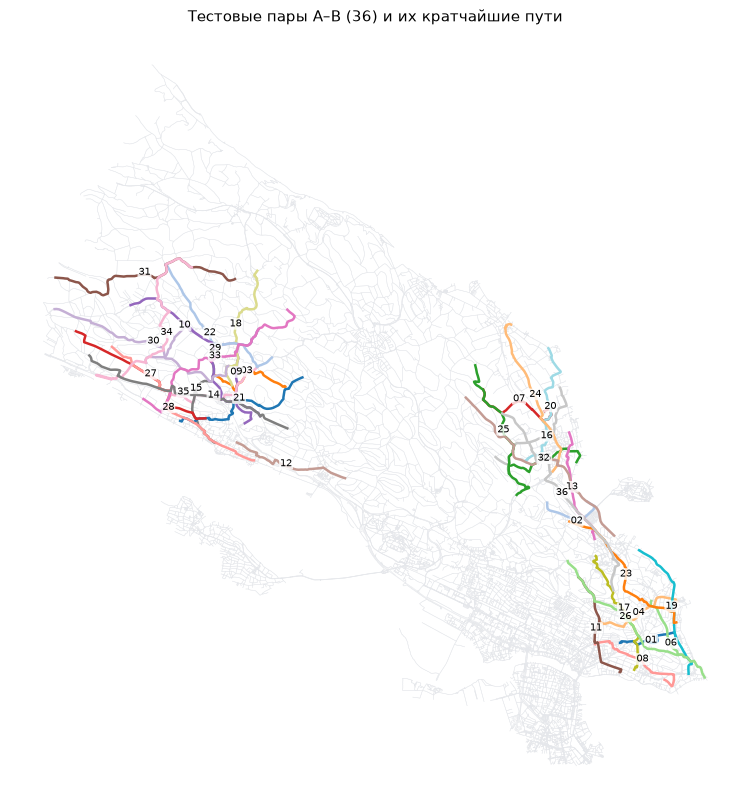

In [6]:
plot_pairs(city);

## 4. Решение ✏️

Стоимость участка = длина × (1 + Σ вес × признак). Плюс — избегать, минус — предпочитать.
`features(roads)` превращает исходные характеристики дорог в числовые признаки.
В примере есть `длина_м` и три признака: велодорожка, крупная дорога, асфальт.
`длина_м` — базовый множитель стоимости; остальные признаки получают веса из `WEIGHTS`.
Меняйте и добавляйте столбцы здесь.
`has_any` проверяет значение среди разделённых `;` тегов участка.
Одна и та же функция передаётся в стоимость и свою ML-модель.

In [7]:
def features(roads):
    f = pd.DataFrame(index=roads.index)
    f["длина_м"] = roads["длина_м"]  # Длина участка в метрах.
    f["велодорожка"] = has_any(roads["тип_дороги"], "велодорожка").astype(float)
    f["крупная_дорога"] = has_any(
        roads["тип_дороги"], {"главная_дорога", "дорога_второго_значения", "скоростная_дорога"}
    ).astype(float)
    f["асфальт"] = has_any(roads["покрытие"], "асфальт").astype(float)
    return f

preview_features(city, features)

,тип_дороги,длина_м,велодорожка,крупная_дорога,асфальт
15522,велодорожка,162.602489,1.0,0.0,1.0
724,дорога_второго_значения,24.278668,0.0,1.0,1.0
641,местная_дорога,17.386630,0.0,0.0,1.0
3352,служебный_проезд,104.082725,0.0,0.0,1.0
694,пешеходная_дорожка,79.261403,0.0,0.0,1.0


### Веса ✏️

Ключи весов — признаки из `features`; `длина_м` уже используется как множитель, отдельный вес ей не нужен.
Быстрая проверка без поиска маршрутов: признаки с весом
на примерах дорог и стоимость участка в последнем столбце.

In [8]:
WEIGHTS = {
    "крупная_дорога": 0.6,
    "велодорожка": -0.4,
    "асфальт": -0.2,
}
my_cost = comfort_cost(WEIGHTS, features=features)
preview_cost(city, my_cost)

,тип_дороги,крупная_дорога,велодорожка,асфальт,длина_м,цена 1 м,стоимость
724,дорога_второго_значения,1.0,0.0,1.0,24.3,1.4,34.0
15522,велодорожка,0.0,1.0,1.0,162.6,0.4,65.0
641,местная_дорога,0.0,0.0,1.0,17.4,0.8,13.9
3352,служебный_проезд,0.0,0.0,1.0,104.1,0.8,83.3
694,пешеходная_дорожка,0.0,0.0,1.0,79.3,0.8,63.4


### Своя формула ✏️

Необязательно: формула целиком — функция `roads → положительная стоимость каждого участка`.
Здесь она использует те же свои признаки; в сравнении ниже это решение «моя формула».

In [9]:
def my_formula(roads):
    f = features(roads)
    return f["длина_м"] * (1 + 0.8 * f["крупная_дорога"] - 0.3 * f["асфальт"])

preview_cost(city, my_formula, features=features)

,тип_дороги,велодорожка,крупная_дорога,асфальт,длина_м,цена 1 м,стоимость
15522,велодорожка,1.0,0.0,1.0,162.6,0.7,113.8
724,дорога_второго_значения,0.0,1.0,1.0,24.3,1.5,36.4
641,местная_дорога,0.0,0.0,1.0,17.4,0.7,12.2
3352,служебный_проезд,0.0,0.0,1.0,104.1,0.7,72.9
694,пешеходная_дорожка,0.0,0.0,1.0,79.3,0.7,55.5


### Повороты ✏️

`my_turn_penalty` получает два направленных участка `(откуда, куда, ключ)` и возвращает штраф в метрах.
`edge_bearings` берёт направления по геометрии: конец входящего участка и начало следующего.
Направление задаётся на круге: 0° / 360° — вверх, 90° — вправо, 180° — вниз, 270° — влево.
Входящее направление — куда мы двигались до точки поворота.
Разность направлений от −180° до 180°: плюс — направо, минус — налево.
Формула в коде учитывает переход через 360°: из 350° в 10° — это +20°, а не −340°.
`%` — остаток от деления; прибавление и вычитание 180° дают угол поворота со знаком.
Стоимость перехода = стоимость следующего участка + штраф. Начало маршрута — без штрафа.
Под кодом — четыре реальных ситуации из выбранной сети: синим показан въезд, зелёным — выезд.
Маленький круг помогает сопоставить направления на карте с углом 0–360°.
В таблице оценки считаются левые, правые повороты и развороты; плавные изгибы до 55° не считаются.

In [10]:
def my_turn_penalty(graph, incoming, outgoing):
    incoming_direction = edge_bearings(graph, incoming)[1]
    outgoing_direction = edge_bearings(graph, outgoing)[0]
    angle = (outgoing_direction - incoming_direction + 180) % 360 - 180
    if abs(angle) <= 25:
        return 0.0  # прямо
    if abs(angle) <= 55:
        return 8.0  # плавный изгиб
    if abs(angle) >= 150:
        return 90.0  # разворот
    return 10.0 if angle > 0 else 30.0  # направо / налево

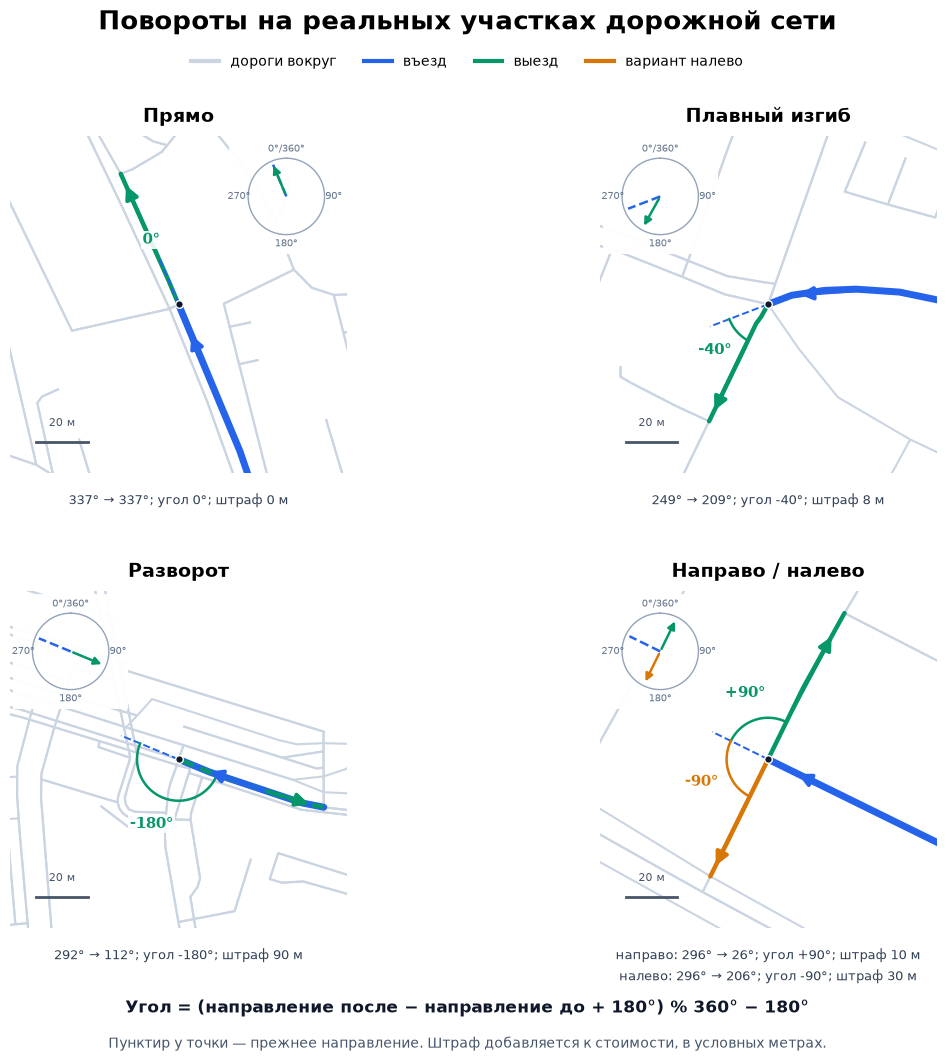

In [11]:
plot_turn_examples(network, my_turn_penalty);

### Поиск ✏️

Обычный Дейкстра из NetworkX ищет минимальную сумму стоимостей.
Жадный поиск ниже написан с нуля: храним пути в списке и выбираем тот, чей конец ближе к цели по прямой.
Длина ребра описывает один участок дороги, а `distance` оценивает оставшееся расстояние до цели.
Квадрат расстояния даёт тот же порядок близости, поэтому извлекать корень не нужно.
Поиск не учитывает стоимости рёбер
и не гарантирует лучший маршрут. Оба алгоритма попадают в сравнение.
С поворотами вершины графа — участки дорог, их координаты — конец участка.

In [12]:
def my_search(graph, source, target, weight="cost"):
    return nx.dijkstra_path(graph, source, target, weight=weight)

def greedy_search(graph, source, target, weight="cost"):
    if source not in graph or target not in graph:
        raise nx.NodeNotFound("Начало или конец отсутствует в графе")

    # Квадрат расстояния от вершины до цели по прямой, а не длина соседнего ребра.
    def distance(node):
        point, goal = graph.nodes[node], graph.nodes[target]
        return (point["x"] - goal["x"])**2 + (point["y"] - goal["y"])**2

    paths = [[source]]  # Начинаем с пути из одной вершины.
    visited = {source}  # Каждую вершину добавляем только один раз, чтобы избежать циклов.

    while paths:
        # Выбираем путь, последняя вершина которого ближе всего к цели.
        path = paths[0]
        for candidate in paths:
            if distance(candidate[-1]) < distance(path[-1]):
                path = candidate
        paths.remove(path)
        current = path[-1]

        if current == target:
            return path  # Путь уже хранится целиком.

        # Продлеваем выбранный путь до каждого ещё не посещённого соседа.
        for neighbor in graph.successors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                paths.append(path + [neighbor])

    # Все доступные вершины проверены, но цель не достигнута.
    raise nx.NetworkXNoPath("Путь не найден")

mine = solution(my_cost, turns=my_turn_penalty, search=my_search, label="моё решение")
formula = solution(my_formula, turns=my_turn_penalty, search=my_search, label="моя формула")
greedy = solution(my_cost, turns=my_turn_penalty, search=greedy_search, label="жадный поиск")

## 5. ML ✏️

Необязательно: модель предсказывает популярность улицы, а прогноз становится признаком `ml_популярность` (0–1).
Готовая модель — градиентный бустинг по тегам OSM.

In [13]:
model = train_popularity(city)

def features_with_ml(roads):
    f = features(roads)
    f["ml_популярность"] = ml_feature(model)(roads)["ml_популярность"]
    return f

ml_cost = comfort_cost(
    {**WEIGHTS, "ml_популярность": -0.8}, features=features_with_ml
)
with_ml = solution(ml_cost, turns=my_turn_penalty, search=my_search, label="моё + ML")

Связь прогноза с реальной популярностью на отложенных улицах: 0.64 (1 — идеально, 0 — никакой)


### Своя модель ✏️

`train_model(x, y)` получает таблицу признаков и цель `log(1 + поездки)`, вызывает `fit`
и возвращает обученную модель. Пример специально слабый — дерево глубины 1; попробуйте лучше.
`train_custom_model` вычисляет `features`, исключает неизвестные поездки,
проверяет модель на отложенных кварталах и затем обучает новую модель на всех открытых метках.

In [14]:
from sklearn.tree import DecisionTreeRegressor

def train_model(x, y):
    model = DecisionTreeRegressor(max_depth=1, random_state=42)
    model.fit(x, y)
    return model

my_model = train_custom_model(city, train_model, features=features)

def features_with_my_model(roads):
    f = features(roads)
    f["ml_популярность"] = ml_feature(my_model)(roads)["ml_популярность"]
    return f

my_ml_cost = comfort_cost(
    {**WEIGHTS, "ml_популярность": -0.8}, features=features_with_my_model
)
with_my_ml = solution(my_ml_cost, turns=my_turn_penalty, search=my_search, label="моё + своя ML")

Признаки модели: длина_м, велодорожка, крупная_дорога, асфальт
Связь прогноза с реальной популярностью на отложенных улицах: 0.40 (1 — идеально, 0 — никакой)


## 6. Сравнение

**популярность** — главный критерий, 0–100. Улица без измерения считается средней (50).
Если маршрут длиннее кратчайшего больше чем на 20%, в оценку этой пары идёт популярность кратчайшего:
большой объезд не даёт выигрыша.

Routes by preset:   0%|          | 0/9 [00:00<?, ?it/s]

Routes by preset:  33%|███▎      | 3/9 [00:00<00:00, 16.52it/s]

Routes by preset:  56%|█████▌    | 5/9 [00:00<00:00,  6.36it/s]

Routes by preset:  67%|██████▋   | 6/9 [00:00<00:00,  5.77it/s]

Routes by preset:  89%|████████▉ | 8/9 [00:01<00:00,  8.20it/s]

Routes by preset: 100%|██████████| 9/9 [00:01<00:00,  8.37it/s]

,популярность,популярнее кратчайшего,"объезд, %",поворотов,"неудобные участки, м","время поиска, мс"
быстрый,72.1,31 из 36,6.7,6.9,0.0,23.32
сбалансированный,71.5,31 из 36,6.4,7.5,0.0,23.87
моё + ML,70.6,21 из 36,13.2,6.0,0.0,20.44
моё + своя ML,69.0,22 из 36,10.5,5.7,0.0,17.47
минимум поворотов,68.9,25 из 36,6.5,3.8,0.0,22.09
моя формула,68.5,25 из 36,3.6,5.5,0.0,16.22
моё решение,66.6,23 из 36,1.9,5.9,0.0,17.60
кратчайший,60.7,—,0.0,7.4,0.0,5.22
жадный поиск,59.8,8 из 36,20.1,13.6,0.0,4.33


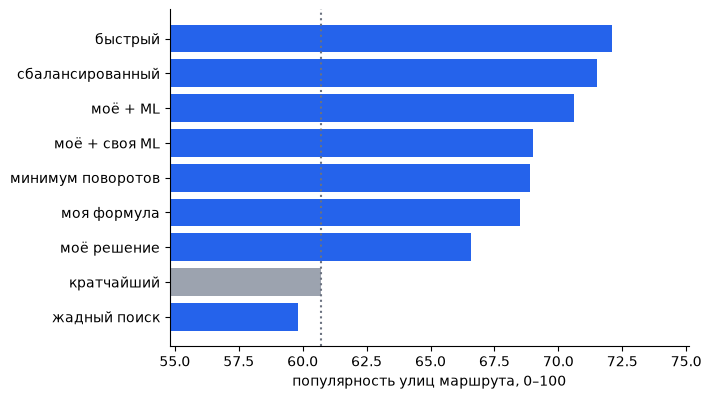

In [15]:
solutions = {
    item["label"]: item
    for item in [mine, formula, greedy, with_ml, with_my_ml, *presets("balanced", "fast", "min_turns").values()]
}
result = score(city, solutions, network=network)
display(result.table)
result.plot();

## 7. Разбор маршрутов

Выберите пару и решение; щелчок по участку покажет его теги.

In [16]:
route_explorer(city, result, filename=OUTPUT / "routes.html")

## 8. Петербург

Решение переносится без изменений; красные линии — реальные поездки (GPX). Совпадение — доля длины маршрута
в пределах 30 м от ближайшей поездки. Подготовленный набор Петербурга должен быть на диске.

In [ ]:
SPB = ROOT / "notebooks/data/hackathon/saint_petersburg"
spb = load_city(SPB)
spb_solutions = {item["label"]: item for item in [mine, with_ml]}
spb_result = score(spb, spb_solutions, network=build_network(spb, keep))
display(gpx_table(spb_result, spb.tracks))
display(route_explorer(spb, spb_result, tracks=spb.tracks, filename=OUTPUT / "spb_routes.html"))

## 9. Сдача ✏️

In [18]:
CHOSEN = mine  # или formula, greedy, with_ml, with_my_ml
folder = export_solution(city, CHOSEN, keep=keep, folder=OUTPUT / "submission")
print("Сдайте папку", folder, "и этот ноутбук")

Сдайте папку D:\PythonProjects\CicleGpx\outputs\hackathon\konstanz_more\submission и этот ноутбук
